In [1]:
import sys
import re
import os
import time
import torch

import numpy as np
import matplotlib.pyplot as plt

# import pandas as pd
# import pyarrow.parquet as pq

# import torch.nn as nn
# import torch.optim as optim
# from torch.utils.data import DataLoader, TensorDataset

# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import MinMaxScaler

# keep modified files updated
%load_ext autoreload
%autoreload 2

In [3]:
from Neural_Network_Model.data_utils import prepare_data, transform_data_with_scalers#, balance_joint_bins
from lib.target_utils import cal_abs_mag, remove_extinction
from Neural_Network_Model.prepare_data import extract_info, read_training_data
from Neural_Network_Model.training_utils import Training

In [2]:
# ✅ Print the path of the current Python interpreter
print("✅ Python interpreter path:")
print(sys.executable)

# ✅ Print the name of the current conda environment (if available)
print("\n✅ Current Conda environment (if any):")
print(os.environ.get("CONDA_DEFAULT_ENV", "Not in a conda environment"))

# ✅ Check whether CUDA is available
print("\n✅ Is CUDA available in PyTorch:")
print("CUDA Available:", torch.cuda.is_available())
print("GPU Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

# ✅ Check if GPU is available and set the computation device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n✅ Using device: {device}")


✅ Python interpreter path:
/home/ziying/anaconda3/envs/NN/bin/python3.10

✅ Current Conda environment (if any):
NN

✅ Is CUDA available in PyTorch:
CUDA Available: True
GPU Device: NVIDIA GeForce RTX 3060 Laptop GPU

✅ Using device: cuda


# Prepare data (All you need to set is here)

In [ ]:
# Set the target name and cluster membership the same as you set in the age-estimation codes.
target = 'HIP 8847'
cluster = ''

if cluster != '':
    cluster_cor = '_' + cluster
target = target.strip()
# Your data for training a Neural Network 
file_training = f'NN{cluster_cor}_linear_age_deviation16_8bands_{target.replace(" ", "_")}.parquet'
# The observed values of your target
file_target = f'NN{cluster_cor}_target_{target.replace(" ", "_")}.parquet'

In [5]:
# extract necessary information

target_name, cluster_name, age_type, bands_num, sigma_deviation = extract_info(file_training)

cluster_name: None
target_name: HIP 8847
age_type: linear
bands_num: 8
sigma_deviation: 16


In [6]:
# read training data and target information

table_training, table_real, obs_mags, obs_err_mags, bands_list, parallax_obs, parallax_obs_err, extinction, extinction_err, extinction_type = \
read_training_data(file_training, file_target)

Training data loaded. Shape: (743717, 20)
Columns of training data:
['Mass', 'logAge', 'MH', 'logTe', 'logL', 'logg', 'Req', 'Rpol', 'vtaneq', 'Inclination']
['omega', 'omega_k', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
****************************************************************************************************
bands_list: ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
bands_err_columns: ['G_err', 'G_BP_err', 'G_RP_err', 'B_T_err', 'V_T_err', 'J_err', 'H_err', 'Ks_err']
****************************************************************************************************
Band G: 6.4238 ± 0.0003
Band G_BP: 6.4928 ± 0.001
Band G_RP: 6.2724 ± 0.0005
Band B_T: 6.666 ± 0.014
Band V_T: 6.461 ± 0.01
Band J: 6.132 ± 0.023
Band H: 6.086 ± 0.024
Band Ks: 6.072 ± 0.018
vsini_obs: 46.9983 ± 0.6261 km/s
parallax_obs: 13.514 ± 0.0258 mas
A_V: 0.0 ± 0.25


In [7]:
# calculate absolute magnitudes without extinction

obs_mags_removed, obs_err_mags_removed = remove_extinction(obs_mags, obs_err_mags, bands_list, extinction, extinction_err, extinction_type)
abs_mags, abs_err_mags = cal_abs_mag(obs_mags_removed, obs_err_mags_removed, parallax_obs, parallax_obs_err)

A_G: 0.0000 ± 0.1973
A_G_BP: 0.0000 ± 0.2505
A_G_RP: 0.0000 ± 0.1472
A_B_T: 0.0000 ± 0.3410
A_V_T: 0.0000 ± 0.2637
A_J: 0.0000 ± 0.0607
A_H: 0.0000 ± 0.0328
A_Ks: 0.0000 ± 0.0195


In [8]:
print(bands_list)
print('abs_mags:', abs_mags)
print('abs_err_mags:', abs_err_mags)

['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
abs_mags: [2.07767745 2.1466672  1.92629452 2.31991501 2.11491509 1.78591509
 1.73991509 1.72591515]
abs_err_mags: [0.19729384 0.25053621 0.14730924 0.34131248 0.26397211 0.0650905
 0.04081388 0.02686001]


# Prepare tensors for training (No more actions hereafter)

In [9]:
X_train, Y_train, dev_train, \
X_val, Y_val, dev_val, \
X_test, Y_test, dev_test, \
scalers= prepare_data(
    table_training,
    abs_mags=abs_mags,
    abs_err_mags=abs_err_mags,
    split_ratio=(0.8, 0.1, 0.1)
)

print('Shape of X_train: ', X_train.shape)
print('Shape of Y_train: ', Y_train.shape)

Shape of X_train:  torch.Size([594973, 6])
Shape of Y_train:  torch.Size([594973, 8])


In [10]:
# data near the target to check performance when training

x_near_target, y_near_target, _, _, _, _, _, _, _, = transform_data_with_scalers(
    table_training, scalers, 
    abs_mags=abs_mags, 
    abs_err_mags=abs_err_mags, 
    deviation=5, 
    split_ratio=(1,0,0)
)


🎯 Filtered training data within 5σ: 228816 samples


# First Training

In [13]:
# Settings of trainings

train_NN = Training(target_name = target_name,
                    bands_list = bands_list,
                    age_type = age_type,
                    cluster_name = cluster_name,
                    sigma_deviation = sigma_deviation,
                    X_train = X_train, 
                    Y_train = Y_train, 
                    X_val = X_val, 
                    Y_val = Y_val,
                    X_test = X_test,
                    Y_test = Y_test,
                    x_near_target = x_near_target,
                    y_near_target = y_near_target,
                    scalers = scalers,
                    epochs=300,
                    batch_size=1024*60,
                    lr_manual_flag=True,
                    )

Training parameters: 300 epochs, 10 batches per epoch


In [14]:
# Training

train_NN.train(improve_threshold = 0.05, max_no_improve=20, early_stop_start_epoch=100, early_stop_lr=1e-6,
               lr_improve_threshold = 0.05, lr_patience=10)


2025-08-26 02:07:41,282 - 📝 Checkpoints of your trained NN model will be saved at: 
 /media/ziying/ZIYING GU/AgeEstimationBeta/Neural_Network_Model/checkpoints_linear_age_HIP_8847
2025-08-26 02:07:41,283 - 🚀 Starting training: ...
2025-08-26 02:07:50,034 - 📉 Epoch 001 | Time: 8.75s | Train Loss: 72042.048054 | Val Loss: 115033.539062 | Target Dev: 0.989097 | LR: 1.00e-03
2025-08-26 02:09:01,837 - 📉 Epoch 010 | Time: 71.80s | Train Loss: 41.127165 | Val Loss: 64.327118 | Target Dev: 0.019679 | LR: 1.00e-03
2025-08-26 02:10:21,826 - 📉 Epoch 020 | Time: 79.99s | Train Loss: 23.155164 | Val Loss: 19.501026 | Target Dev: 0.010210 | LR: 1.00e-03
2025-08-26 02:11:41,722 - 📉 Epoch 030 | Time: 79.90s | Train Loss: 18.465558 | Val Loss: 14.849879 | Target Dev: 0.009047 | LR: 1.00e-03
2025-08-26 02:12:53,777 - 🔽 Epoch 039 | Triggering manual LR reduction due to insufficient improvement.
2025-08-26 02:12:53,778 -                Manually reduced LR: 1.00e-03 → 5.00e-04
2025-08-26 02:13:02,102 - 📉 E

2025-08-25 22:46:50,042 - 📉 Epoch 001 | Time: 8.21s | Train Loss: 72145.730895 | Val Loss: 121638.757812 | Target Dev: 1.087090 | LR: 1.00e-03
2025-08-25 22:48:01,625 - 📉 Epoch 010 | Time: 71.58s | Train Loss: 58.437910 | Val Loss: 44.005421 | Target Dev: 0.014289 | LR: 1.00e-03
2025-08-25 22:49:21,319 - 📉 Epoch 020 | Time: 79.69s | Train Loss: 31.802236 | Val Loss: 48.668739 | Target Dev: 0.014608 | LR: 1.00e-03
2025-08-25 22:50:40,863 - 📉 Epoch 030 | Time: 79.54s | Train Loss: 30.530202 | Val Loss: 39.377804 | Target Dev: 0.012579 | LR: 1.00e-03
2025-08-25 22:50:56,831 - 🔽 Epoch 032 | Triggering manual LR reduction due to insufficient improvement.
2025-08-25 22:50:56,832 -                Manually reduced LR: 1.00e-03 → 5.00e-04
2025-08-25 22:52:01,527 - 📉 Epoch 040 | Time: 80.66s | Train Loss: 37.089494 | Val Loss: 12.575126 | Target Dev: 0.007746 | LR: 5.00e-04
2025-08-25 22:52:49,360 - 🔽 Epoch 046 | Triggering manual LR reduction due to insufficient improvement.
2025-08-25 22:52:49

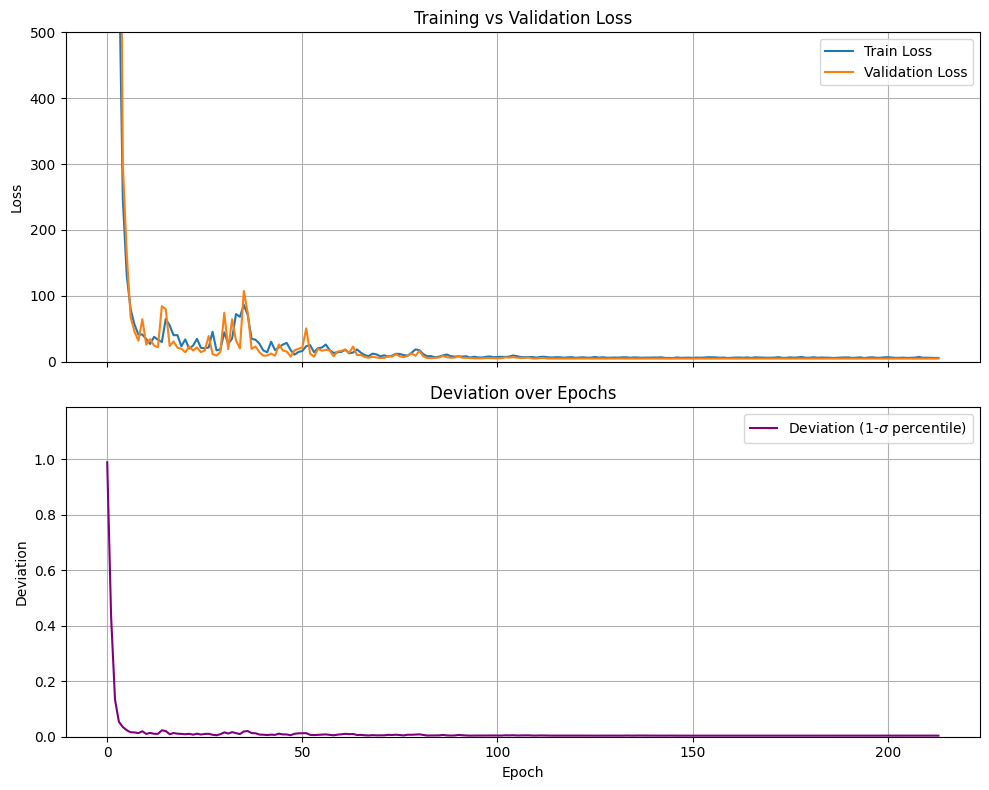

In [15]:
# Plot the evolution of training loss and validation loss,
# as well as the deviations of prediction of near-target data points.

train_NN.plot_loss_dev()

In [16]:
# Test the performance on the testing group

train_NN.run_test_set()

🧪 Final test loss: 4.497162


2025-08-26 02:36:49,997 - 🎯 The evaluation of your trained model is save at: 
 /media/ziying/ZIYING GU/AgeEstimationBeta/Neural_Network_Model/trained_model/NN_model_evaluation_HIP_8847_linear_age_deviation16_input6_output8.pdf


📦 Model loaded from Neural_Network_Model/checkpoints_linear_age_HIP_8847/Best_model_HIP_8847_val4.468266_dev0.003806.pt


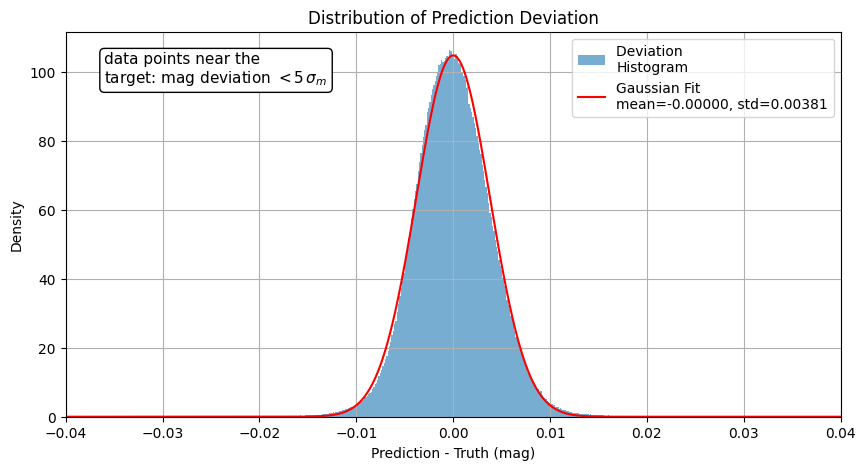

['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
Dev in each band:  [0.00419417 0.00419278 0.00339966 0.0054683  0.00407402 0.0035369
 0.003454   0.00352499]


In [17]:
# Plot the distribution of prediction deviation.
# It should be nearly Gaussian.

train_NN.evaluate()

In [18]:
# Save the NN model.

train_NN.save_NN_model()

2025-08-26 02:36:51,549 - 📦 Your trained model together scalers is saved at: 
 /media/ziying/ZIYING GU/AgeEstimationBeta/Neural_Network_Model/Neural_Network_Model/trained_model/NN_model_HIP_8847_linear_age_deviation16_input6_output8.pt


# You can restart this kernel to release the GPU memory.